# 03 Model B: does this drug cause heart trouble?

This answers **condition 3** of the chain: *if this drug builds up in the blood, does it cause a dangerous heart rhythm?*

**What hERG is.** A channel in heart muscle cells that lets potassium out, which is how the heart resets electrically between beats. Block that channel and the reset drags. On an ECG the gap called the **QT interval** gets longer, and if it stretches far enough the heartbeat can break down into a rhythm that does not pump blood. This is a real and well-known reason drugs get pulled from the market.

**Target:** ROC-AUC of 0.85 or better. (ROC-AUC is the chance the model scores a real yes above a real no: 0.5 is a coin flip, 1.0 is perfect.)

**The difficulty here is that there are only 655 molecules.** That is small. Test on one random slice of it and the score bounces around depending on which molecules happened to land in the slice. So this notebook tests five different ways and reports **how much the answer moves**, not just the average. A number without its spread would look far more solid than it is.

**Model B is a fallback, not the first choice.** Where a drug has a real lab hERG measurement (notebook 05 collects those), the measurement is used and Model B is never consulted. Model B only answers for drugs where no measurement exists.

In [1]:
import sys
import importlib
import os

sys.path.append(os.path.abspath(os.path.join("..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

import features
import models

PROCESSED_DIR = os.path.join("..", "data", "processed")

# Python only reads a file from src/ the FIRST time it is imported. After that
# it serves a cached copy, so any edit you make to src/ is invisible to a
# notebook that has already run this cell.
#
# The symptom is confusing: an AttributeError saying a function does not exist,
# when you can see it sitting right there in the file. Reloading here means
# "Run All" always uses what is actually on disk.
for module in (features, models):
    importlib.reload(module)

## Load the data

In [2]:
X = np.load(os.path.join(PROCESSED_DIR, "X_herg.npy"))
y = np.load(os.path.join(PROCESSED_DIR, "y_herg.npy"))
herg_df = pd.read_csv(os.path.join(PROCESSED_DIR, "herg_clean.csv"))

print("X:", X.shape)
print("label counts:", np.bincount(y.astype(int)))
print("positive fraction:", round(float(y.mean()), 3))
print()
print(f"{X.shape[0]} compounds is small. One 20% holdout is only "
      f"{int(X.shape[0] * 0.2)} test molecules, which is why the number below")
print("is a cross validated mean with a standard deviation attached.")

X: (655, 2058)
label counts: [204 451]
positive fraction: 0.689

655 compounds is small. One 20% holdout is only 131 test molecules, which is why the number below
is a cross validated mean with a standard deviation attached.


## Testing

**Cross validation:** cut the data into five slices. Train on four, test on the one left out, and repeat so every slice gets its turn. Every molecule gets tested exactly once, and we get five scores instead of one.

The spread of those five is reported alongside the average. On a dataset this small the average on its own looks much more trustworthy than it deserves.

In [3]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_aucs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    model = models.train_rf(X[train_idx], y[train_idx])
    fold_auc = models.get_auc(model, X[test_idx], y[test_idx])
    fold_aucs.append(fold_auc)
    print(f"  fold {fold}: ROC-AUC {fold_auc:.4f}  "
          f"(train {len(train_idx)}, test {len(test_idx)})")

fold_aucs = np.array(fold_aucs)
mean_auc, std_auc = fold_aucs.mean(), fold_aucs.std()
print()
print(f"cross validated ROC-AUC: {mean_auc:.4f} +/- {std_auc:.4f}")
print(f"fold range: {fold_aucs.min():.4f} to {fold_aucs.max():.4f}")
print(f"target >= 0.85 -> {'MET' if mean_auc >= 0.85 else 'NOT MET'}")

  fold 1: ROC-AUC 0.8750  (train 524, test 131)


  fold 2: ROC-AUC 0.8951  (train 524, test 131)


  fold 3: ROC-AUC 0.8407  (train 524, test 131)


  fold 4: ROC-AUC 0.8821  (train 524, test 131)


  fold 5: ROC-AUC 0.9062  (train 524, test 131)

cross validated ROC-AUC: 0.8798 +/- 0.0223
fold range: 0.8407 to 0.9062
target >= 0.85 -> MET


## Now the honest version, and the number we report

Same idea as notebook 02: group molecules by their bare ring skeleton so near-identical molecules cannot sit on both sides, and the model is tested on skeletons it has genuinely never seen.

But doing that as **one** split here would leave only ~130 molecules to test on, and the score would swing with the random seed. So we combine both ideas:

- five folds, so every molecule is tested exactly once
- no skeleton ever appears on both sides of a fold
- the blocker/non-blocker balance held steady in each fold

That keeps the honesty of the skeleton split and adds the stability of cross validation. **This is the number to quote**, together with its spread.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

# One skeleton label per molecule. Molecules with the same label are forced
# into the same fold, which is what makes this harder than plain cross
# validation and is the whole point.
scaffolds = np.array(models.scaffold_groups(herg_df["Drug"].tolist()))
print(f"{len(set(scaffolds))} distinct scaffolds over {len(scaffolds)} compounds\n")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scaffold_aucs = []
for fold, (tr, te) in enumerate(sgkf.split(X, y, groups=scaffolds), start=1):
    model_sc = models.train_rf(X[tr], y[tr])
    scaffold_aucs.append(roc_auc_score(y[te], model_sc.predict_proba(X[te])[:, 1]))
    print(f"  fold {fold}: ROC-AUC {scaffold_aucs[-1]:.4f}  (train {len(tr)}, test {len(te)})")

scaffold_aucs = np.array(scaffold_aucs)
sc_auc, sc_std = scaffold_aucs.mean(), scaffold_aucs.std()

print(f"\nplain cross validated : {mean_auc:.4f} +/- {std_auc:.4f}")
print(f"scaffold grouped      : {sc_auc:.4f} +/- {sc_std:.4f}")
print(f"drop once analogues are separated: {mean_auc - sc_auc:.4f}")
print(f"\ntarget >= 0.85 -> {'MET' if sc_auc >= 0.85 else 'NOT MET'}")

393 distinct scaffolds over 655 compounds



  fold 1: ROC-AUC 0.8582  (train 523, test 132)


  fold 2: ROC-AUC 0.8125  (train 524, test 131)


  fold 3: ROC-AUC 0.9100  (train 525, test 130)


  fold 4: ROC-AUC 0.8795  (train 523, test 132)


  fold 5: ROC-AUC 0.8868  (train 525, test 130)

plain cross validated : 0.8798 +/- 0.0223
scaffold grouped      : 0.8694 +/- 0.0329
drop once analogues are separated: 0.0104

target >= 0.85 -> MET


### Why a random forest here, when Model A used gradient boosting?

The answer genuinely flips between the two datasets, so this is measured on the same folds rather than claimed.

**It comes down to how much data there is.** Gradient boosting builds trees one after another, each one trying to fix what the last one got wrong. That only helps if "got wrong" marks a real pattern. With 12,328 molecules, Model A has enough data for that to be true, and boosting wins.

With 655 molecules, "got wrong" is often just noise, and boosting dutifully memorises the noise. A random forest instead grows many independent trees and averages their votes, and averaging is exactly the right move when data is scarce.

Same two algorithms, opposite answers, and the only thing that changed is the amount of data.

In [5]:
# Both algorithms, identical folds, identical features. The only difference is
# the algorithm, so the comparison is fair.
rows = []
for name, train_fn in (("RandomForest", models.train_rf),
                       ("GradientBoosting", models.train_model)):
    aucs = [roc_auc_score(y[te], train_fn(X[tr], y[tr]).predict_proba(X[te])[:, 1])
            for tr, te in sgkf.split(X, y, groups=scaffolds)]
    aucs = np.array(aucs)
    rows.append({"algorithm": name,
                 "scaffold_AUC": round(float(aucs.mean()), 4),
                 "sd": round(float(aucs.std()), 4),
                 "meets_0.85": "yes" if aucs.mean() >= 0.85 else "NO"})

print(pd.DataFrame(rows).to_string(index=False))
print()
print("The forest wins here. In notebook 02, on 12,328 compounds, boosting won.")
print("Same two algorithms, opposite answers, because only the data size changed.")

       algorithm  scaffold_AUC     sd meets_0.85
    RandomForest        0.8694 0.0329        yes
GradientBoosting        0.8468 0.0470         NO

The forest wins here. In notebook 02, on 12,328 compounds, boosting won.
Same two algorithms, opposite answers, because only the data size changed.


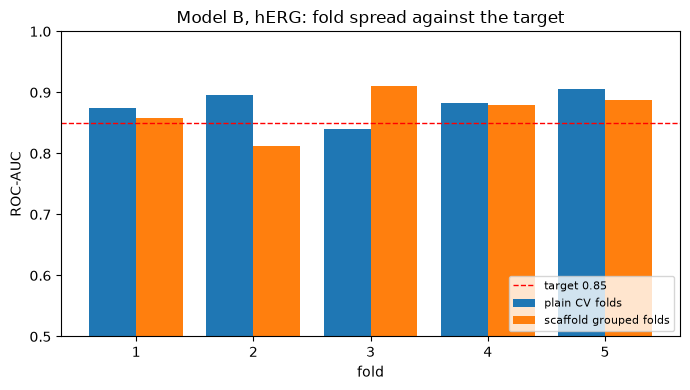

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(1, 6) - 0.2, fold_aucs, width=0.4, label="plain CV folds")
ax.bar(np.arange(1, 6) + 0.2, scaffold_aucs, width=0.4, label="scaffold grouped folds")
ax.axhline(0.85, color="red", linestyle="--", linewidth=1, label="target 0.85")
ax.set_xlabel("fold")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.5, 1.0)
ax.set_title("Model B, hERG: fold spread against the target")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## Train the final model on everything

The testing is finished, so the model we actually save is retrained on **all** 655 molecules. More data makes a better model, and we have already got our honest score.

**Its score is the cross-validated number above.** Do not re-score this final model on the same molecules it just trained on — that would be marking its own homework, and it would look fantastic for no reason.

In [7]:
model_b = models.train_rf(X, y)
joblib.dump(model_b, os.path.join(PROCESSED_DIR, "model_b.joblib"))

metrics = {
    "model": "B (hERG)",
    "n_compounds": int(X.shape[0]),
    "positive_fraction": round(float(y.mean()), 4),
    "roc_auc_cv_mean": round(float(mean_auc), 4),
    "roc_auc_cv_std": round(float(std_auc), 4),
    "roc_auc_scaffold_grouped": round(float(sc_auc), 4),
    "roc_auc_scaffold_std": round(float(sc_std), 4),
    "target": 0.85,
}
print("saved model_b.joblib\n")
for key, value in metrics.items():
    print(f"  {key}: {value}")

saved model_b.joblib

  model: B (hERG)
  n_compounds: 655
  positive_fraction: 0.6885
  roc_auc_cv_mean: 0.8798
  roc_auc_cv_std: 0.0223
  roc_auc_scaffold_grouped: 0.8694
  roc_auc_scaffold_std: 0.0329
  target: 0.85
